# Thành viên 3 Trích xuất đặc trưng từng hạt

**Đầu vào:** kết quả notebook 01 và 02. Kernel mới chỉ đọc file bàn giao.
Đặc trưng gồm hình dạng, màu sắc RGB/HSV và kết cấu GLCM.
Chiều dài, chu vi và diện tích quy về pixel ảnh gốc; không phải mm.

In [1]:
from pathlib import Path
from dataclasses import dataclass
from types import SimpleNamespace
import os
import json
import hashlib
import math
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage.morphology import h_maxima
from skimage.feature import graycoprops
from IPython.display import display, Markdown

# Mặc định: đặt notebook cạnh raw_dataset và batch_dataset.
# Có thể đổi PROJECT_ROOT sang đường dẫn thư mục dữ liệu của bạn.
PROJECT_ROOT = Path(os.environ.get("RICE_DATA_ROOT", Path.cwd())).resolve()
OUTPUT_ROOT = Path(os.environ.get("RICE_OUTPUT_ROOT", PROJECT_ROOT / "outputs" / "notebook")).resolve()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"

In [2]:
SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

def decode_image(data: bytes) -> np.ndarray:
    image = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError('Không đọc được ảnh. Hãy dùng ảnh JPG, PNG, BMP hoặc TIFF hợp lệ.')
    return image

def read_image(path) -> np.ndarray:
    return decode_image(Path(path).read_bytes())

def write_image(path, image: np.ndarray) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, encoded = cv2.imencode(path.suffix, image)
    if not ok:
        raise OSError(f'Không mã hóa được ảnh {path}')
    path.write_bytes(encoded.tobytes())

In [3]:
def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def load_stage1():
    folder = OUTPUT_ROOT / "01_du_lieu"
    path = folder / "manifest.csv"
    if not path.is_file():
        raise FileNotFoundError("Chưa có manifest.csv. Hãy chạy notebook 01 trước.")
    frame = pd.read_csv(path, keep_default_na=False)
    valid = frame[(frame["status"] == "ok") & (frame["duplicate_of"] == "")].copy()
    if valid.empty:
        raise ValueError("Không có ảnh hợp lệ duy nhất để xử lý.")
    return frame, valid, file_sha256(path)


def choose_demo(frame):
    matches = frame[frame["image_path"] == "raw_dataset/Tot/picT (1).png"]
    return (matches if len(matches) else frame).iloc[0]


def require_handoff(folder, expected_key, expected_value):
    path = Path(folder) / "handoff.json"
    if not path.is_file():
        raise FileNotFoundError(f"Chưa có {path.name} ở bước trước. Hãy chạy notebook theo thứ tự.")
    info = json.loads(path.read_text(encoding="utf-8"))
    if info.get(expected_key) != expected_value:
        raise ValueError("Dữ liệu bước trước đã thay đổi. Hãy chạy lại các notebook phía sau theo thứ tự.")
    return info

In [4]:
STAGE1 = OUTPUT_ROOT / "01_du_lieu"
STAGE2 = OUTPUT_ROOT / "02_phan_doan"
STAGE3 = OUTPUT_ROOT / "03_dac_trung"
STAGE3.mkdir(parents=True, exist_ok=True)
manifest, valid_images, manifest_hash = load_stage1()
stage2_info = require_handoff(STAGE2, "stage1_manifest_sha256", manifest_hash)
if file_sha256(STAGE2 / "regions.csv") != stage2_info["regions_sha256"] or file_sha256(STAGE2 / "images.csv") != stage2_info["images_sha256"]:
    raise ValueError("Bảng phân đoạn đã bị sửa. Hãy chạy lại notebook 02.")
regions = pd.read_csv(STAGE2 / "regions.csv")
segmented_images = pd.read_csv(STAGE2 / "images.csv", keep_default_na=False)
COMPUTE_TEXTURE = True
EXCLUDE_LARGE_ROUND_OBJECTS = True
PIXEL_COLOR_RULES = dict(yellow_h_min=10, yellow_h_max=40, yellow_s_min=55, yellow_v_min=65, dark_v_max=85)

## Công thức và quy ước đo

- Dài/rộng: hai cạnh của minAreaRect, dài ≥ rộng; Aspect Ratio = dài/rộng.
- Circularity = 4πA/P²; Solidity = A/diện tích bao lồi.
- Màu lấy từ ảnh màu chưa cân bằng histogram, chỉ trong mask; co một pixel ở viền khi đủ diện tích
  để giảm lẫn nền. Lưu số pixel đo màu để truy nguyên.
- H của OpenCV: 0–179; S/V: 0–255. Ngưỡng pixel hiện là thử nghiệm.
- GLCM lượng tử hóa 32 mức, khoảng cách một pixel, bốn hướng. Chỉ đếm cặp có cả hai đầu trong mask.

Bộ lọc vật lớn gần tròn giúp giảm đếm nhầm đồng xu, không nhận dạng mọi loại tạp chất.
Có thể tắt bằng `EXCLUDE_LARGE_ROUND_OBJECTS=False` và chạy lại notebook 03–04.

In [5]:
COLOR_DEFAULTS = dict(yellow_h_min=10, yellow_h_max=40, yellow_s_min=55,
                      yellow_v_min=65, dark_v_max=85)

FEATURE_COLUMNS = ['grain_id', 'area', 'pixel_area', 'perimeter', 'length', 'width',
                   'aspect_ratio', 'circularity', 'solidity', 'mean_r', 'mean_g', 'mean_b',
                   'mean_h', 'mean_s', 'mean_v', 'yellow_fraction', 'dark_fraction', 'color_pixel_count',
                   'glcm_contrast', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation',
                   'texture_pairs', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h',
                   'center_x', 'center_y', 'touches_border', 'was_split', 'feature_valid',
                   'object_type', 'exclusion_reason']

def masked_glcm(gray, mask, levels=32):
    """Count only pairs whose BOTH endpoints are in the grain (no background texture)."""
    q = np.minimum(gray.astype(np.int32) * levels // 256, levels - 1)
    matrices = []
    pair_count = 0
    h, w = gray.shape
    for dy, dx in [(0, 1), (1, 0), (1, 1), (1, -1)]:
        ya, yb = slice(max(0, -dy), min(h, h-dy)), slice(max(0, dy), min(h, h+dy))
        xa, xb = slice(max(0, -dx), min(w, w-dx)), slice(max(0, dx), min(w, w+dx))
        valid = mask[ya, xa] & mask[yb, xb]
        a, b = q[ya, xa][valid], q[yb, xb][valid]
        if not a.size:
            continue
        matrix = np.bincount(a * levels + b, minlength=levels*levels).reshape(levels, levels).astype(float)
        matrix += matrix.T
        matrices.append(matrix / matrix.sum())
        pair_count += int(a.size)
    if not matrices:
        return {**{f'glcm_{k}': np.nan for k in ['contrast', 'homogeneity', 'energy', 'correlation']}, 'texture_pairs': 0}
    glcm = np.stack(matrices, axis=-1)[:, :, None, :]
    return {**{f'glcm_{k}': float(graycoprops(glcm, k).mean()) for k in ['contrast', 'homogeneity', 'energy', 'correlation']},
            'texture_pairs': pair_count}

def extract_features(preprocessed, segmentation, color_rules=None, texture=True, exclude_large_round=True):
    rules = {**COLOR_DEFAULTS, **(color_rules or {})}
    if not 0 <= rules['yellow_h_min'] <= rules['yellow_h_max'] <= 179:
        raise ValueError('Khoảng H phải thỏa 0 <= H_min <= H_max <= 179 theo OpenCV.')
    if any(not 0 <= rules[k] <= 255 for k in ['yellow_s_min','yellow_v_min','dark_v_max']):
        raise ValueError('Ngưỡng S và V phải nằm trong [0,255].')
    rows = []
    sx, sy = preprocessed.scale_x, preprocessed.scale_y
    for region in segmentation.regions:
        x, y, w, h = region.bbox
        mask = region.mask > 0
        color = preprocessed.color[y:y+h, x:x+w]
        hsv = cv2.cvtColor(color, cv2.COLOR_BGR2HSV)
        # Otsu/blur can add a thin background halo; sample the interior for color.
        core = cv2.erode(region.mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3)),
                         borderType=cv2.BORDER_CONSTANT,borderValue=0) > 0
        color_mask = core if core.sum() >= max(3, mask.sum()*0.5) else mask
        pixels, hp = color[color_mask], hsv[color_mask]
        contour = region.contour.astype(np.float32) / np.array([sx, sy], np.float32)
        area = float(cv2.contourArea(contour))
        perimeter = float(cv2.arcLength(contour, True))
        length, width = sorted(cv2.minAreaRect(contour)[1], reverse=True)
        hull_area = cv2.contourArea(cv2.convexHull(contour))
        yellow = ((hp[:, 0] >= rules['yellow_h_min']) & (hp[:, 0] <= rules['yellow_h_max']) &
                  (hp[:, 1] >= rules['yellow_s_min']) & (hp[:, 2] >= rules['yellow_v_min']))
        b, g, r = pixels.mean(axis=0)
        mh, ms, mv = hp.mean(axis=0)
        row = dict(grain_id=region.grain_id, area=area, pixel_area=float(mask.sum()/(sx*sy)),
                   perimeter=perimeter, length=float(length), width=float(width),
                   aspect_ratio=float(length/width) if width else 0.0,
                   circularity=float(4*np.pi*area/perimeter**2) if perimeter else 0.0,
                   solidity=float(area/hull_area) if hull_area else 0.0,
                   mean_r=float(r), mean_g=float(g), mean_b=float(b), mean_h=float(mh), mean_s=float(ms), mean_v=float(mv),
                   yellow_fraction=float(yellow.mean()), dark_fraction=float((hp[:, 2] <= rules['dark_v_max']).mean()),
                   color_pixel_count=int(color_mask.sum()),
                   bbox_x=x/sx, bbox_y=y/sy, bbox_w=w/sx, bbox_h=h/sy,
                   center_x=region.centroid[0]/sx, center_y=region.centroid[1]/sy,
                   touches_border=region.touches_border, was_split=region.was_split,
                   feature_valid=bool(area > 0 and width > 0), object_type='candidate_grain', exclusion_reason='')
        row.update(masked_glcm(preprocessed.gray[y:y+h, x:x+w], mask) if texture else
                   {**{f'glcm_{k}': np.nan for k in ['contrast', 'homogeneity', 'energy', 'correlation']}, 'texture_pairs': 0})
        rows.append(row)
    frame = pd.DataFrame(rows, columns=FEATURE_COLUMNS)
    # A conservative, optional coin/large-object filter, not a general impurity detector.
    if len(frame) and exclude_large_round:
        median = float(frame.pixel_area.median())
        excluded = (frame.pixel_area > median*5) & (frame.aspect_ratio < 1.4) & (frame.circularity > 0.70)
        frame.loc[excluded, 'object_type'] = 'excluded_object'
        frame.loc[excluded, 'exclusion_reason'] = 'large_round_object'
    return frame

## Khôi phục từng ROI và mask từ file bàn giao

In [6]:
def restore_segmentation(image_id, labels):
    items = []
    for row in regions[regions.image_id == image_id].itertuples(index=False):
        x, y, w, h = map(int, (row.x, row.y, row.w, row.h))
        mask = (labels[y:y+h, x:x+w] == row.grain_id).astype(np.uint8) * 255
        cc, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not cc:
            raise ValueError(f"Mask rỗng ở ảnh {image_id}, ID {row.grain_id}.")
        contour = max(cc, key=cv2.contourArea) + np.array([[[x, y]]], np.int32)
        items.append(SimpleNamespace(grain_id=int(row.grain_id), bbox=(x, y, w, h), mask=mask,
                                     contour=contour, centroid=(float(row.center_x), float(row.center_y)),
                                     touches_border=bool(row.touches_border), was_split=bool(row.was_split)))
    return SimpleNamespace(regions=items)

## Tạo bảng đặc trưng cho toàn bộ ảnh

In [7]:
frames = []
for i, row in enumerate(valid_images.itertuples(index=False), 1):
    info = segmented_images[segmented_images.image_id == row.image_id].iloc[0]
    color = read_image(STAGE1 / row.color_path)
    with np.load(STAGE2 / info.instance_path, allow_pickle=False) as stored:
        labels = stored["labels"]
    pre = SimpleNamespace(color=color, gray=cv2.cvtColor(color, cv2.COLOR_BGR2GRAY),
                          scale_x=float(row.scale_x), scale_y=float(row.scale_y))
    seg = restore_segmentation(row.image_id, labels)
    frame = extract_features(pre, seg, PIXEL_COLOR_RULES, COMPUTE_TEXTURE, EXCLUDE_LARGE_ROUND_OBJECTS)
    frame.insert(0, "split", row.split)
    frame.insert(0, "image_path", row.image_path)
    frame.insert(0, "image_id", row.image_id)
    frames.append(frame)
    if i % 10 == 0 or i == len(valid_images):
        print(f"Đã đo đặc trưng {i}/{len(valid_images)} ảnh")
features = pd.concat(frames, ignore_index=True)
features.to_csv(STAGE3 / "features.csv", index=False, encoding="utf-8-sig")
numeric_required = ["area", "length", "width", "mean_v", "yellow_fraction", "dark_fraction"]
if len(features) and not np.isfinite(features[numeric_required].to_numpy()).all():
    raise ValueError("Có đặc trưng hình dạng/màu thiếu hoặc không hữu hạn.")
handoff = dict(stage1_manifest_sha256=manifest_hash,
               stage2_handoff_sha256=file_sha256(STAGE2 / "handoff.json"),
               features_sha256=file_sha256(STAGE3 / "features.csv"), rows=len(features), images=len(valid_images),
               config=dict(texture=COMPUTE_TEXTURE, exclude_large_round=EXCLUDE_LARGE_ROUND_OBJECTS,
                           pixel_color_rules=PIXEL_COLOR_RULES))
(STAGE3 / "handoff.json").write_text(json.dumps(handoff, ensure_ascii=False, indent=2), encoding="utf-8")
display(features[["image_path", "grain_id", "area", "length", "width", "aspect_ratio", "mean_v", "yellow_fraction", "dark_fraction", "object_type"]].head(15))
print("Tổng dòng đặc trưng:", len(features))

Đã đo đặc trưng 10/67 ảnh


Đã đo đặc trưng 20/67 ảnh


Đã đo đặc trưng 30/67 ảnh


Đã đo đặc trưng 40/67 ảnh


Đã đo đặc trưng 50/67 ảnh


Đã đo đặc trưng 60/67 ảnh


Đã đo đặc trưng 67/67 ảnh


,image_path,grain_id,area,length,width,aspect_ratio,mean_v,yellow_fraction,dark_fraction,object_type
0,batch_dataset/picCacloaigao (1).jpg,1,3959.785809,140.903717,34.008049,4.143246,141.225859,0.913257,0.0,candidate_grain
1,batch_dataset/picCacloaigao (1).jpg,2,3322.440177,126.320274,33.524288,3.768023,138.246124,0.992248,0.0,candidate_grain
2,batch_dataset/picCacloaigao (1).jpg,3,4434.837128,159.671677,33.644978,4.745780,136.351825,0.681752,0.0,candidate_grain
3,batch_dataset/picCacloaigao (1).jpg,4,3257.527541,129.938461,35.260361,3.685114,134.932673,0.000000,0.0,candidate_grain
4,batch_dataset/picCacloaigao (1).jpg,5,3124.746864,116.599213,34.011246,3.428255,132.438669,0.686071,0.0,candidate_grain
5,batch_dataset/picCacloaigao (1).jpg,6,2879.837261,116.632492,31.162094,3.742768,143.990888,0.000000,0.0,candidate_grain
6,batch_dataset/picCacloaigao (1).jpg,7,1012.076021,54.321842,26.072844,2.083464,142.731544,0.000000,0.0,candidate_grain
7,batch_dataset/picCacloaigao (1).jpg,8,1552.043701,71.072609,26.779528,2.653990,138.094017,0.000000,0.0,candidate_grain
8,batch_dataset/picCacloaigao (1).jpg,9,4266.650444,144.290192,34.354950,4.199983,133.007440,0.002976,0.0,candidate_grain
9,batch_dataset/picCacloaigao (1).jpg,10,3239.821207,119.223724,33.379410,3.571774,144.583665,0.577689,0.0,candidate_grain


Tổng dòng đặc trưng: 14415


## Khảo sát phân bố đặc trưng của ảnh minh họa

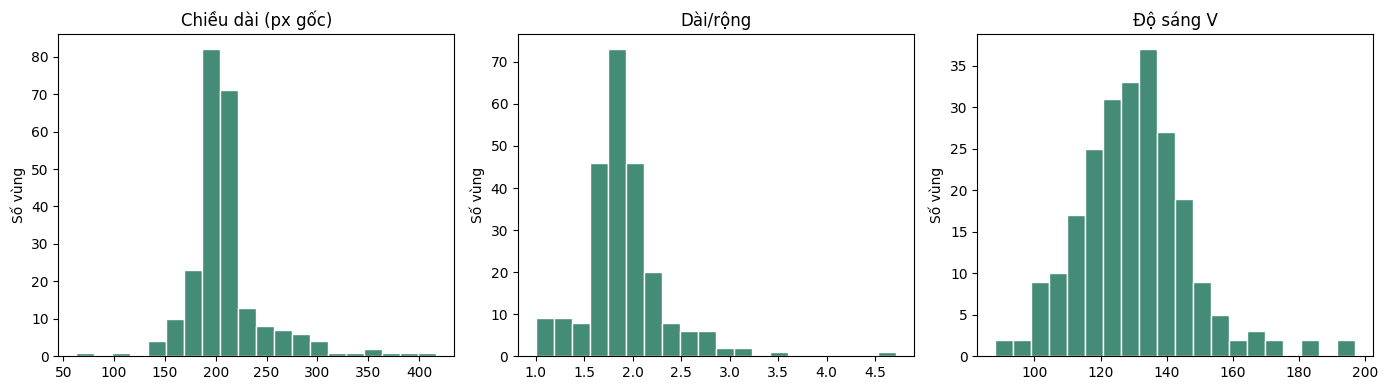

In [8]:
demo = choose_demo(valid_images)
sample = features[(features.image_id == demo.image_id) & (features.object_type == "candidate_grain")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(axes, ["length", "aspect_ratio", "mean_v"], ["Chiều dài (px gốc)", "Dài/rộng", "Độ sáng V"]):
    ax.hist(sample[col], bins=20, color="#458c78", edgecolor="white")
    ax.set_title(title)
    ax.set_ylabel("Số vùng")
plt.tight_layout()
plt.show()

## Kiểm tra GLCM và bàn giao cho thành viên 4

Nếu tắt GLCM hoặc không có cặp pixel hợp lệ, đặc trưng kết cấu để trống và `texture_pairs=0`;
không thay giá trị thiếu bằng số giả. GLCM chưa dùng để gán nhãn bất thường.
Sản phẩm: `03_dac_trung/features.csv` và `handoff.json`.

In [9]:
test_gray = np.full((20, 20), 160, np.uint8)
test_mask = np.zeros((20, 20), bool)
test_mask[5:15, 5:15] = True
before = masked_glcm(test_gray, test_mask)
test_gray[~test_mask] = np.arange((~test_mask).sum()) % 256
assert before == masked_glcm(test_gray, test_mask)
assert before["glcm_contrast"] == 0.0
assert len(features) == len(regions)
assert not features.duplicated(["image_id", "grain_id"]).any()
print("Đạt: GLCM không tính nền; mỗi vùng có đúng một dòng đặc trưng.")

Đạt: GLCM không tính nền; mỗi vùng có đúng một dòng đặc trưng.
